# Contrast curve with KLIP forward modeling

Detection limits for an IFS ADI sequence with `jighcontrast.jFM.contrast_curve`:
at each separation the KLIP throughput and the matched-filter template come from
the forward model (no fake-planet injections), the noise is measured around the
ring, channels are combined with their measured (correlated) noise, and the limit
is quoted at the false-alarm probability of a Gaussian 5 sigma with small-sample
(Student-t) statistics. The PSF calibration is one or two unocculted snapshots,
as in a real observing run.

Calibration follows a real observing sequence without satellite spots: the star
position in the coronagraphic frames is the coronagraph's position on the detector
(`STAR_CENTER`, a fixed number), and the unocculted snapshots only provide the PSF
(each centered on its own peak) and the flux scale.

**To use with your data, edit only the configuration cell.** As committed it runs
on the simulated SCALES HIP 21152 example data. Methods and validation:
[README](../README.md), [validation](../validation/README.md).

In [1]:
import os
import numpy as np

# ---- data (same layout as the scalesETC simulations) --------------------------
DATA_DIR = "."
CORONAGRAPH_FILE = "HIP21152_SCALES_L_3h_coronagraph.fits"  # (n_exp, n_wave, ny, nx)
UNOCCULTED_FILE = "HIP21152_SCALES_L_3h_unocculted.fits"    # unocculted exposure(s), same layout
PSF_SNAPSHOTS = [0, -1]     # unocculted exposures used as the PSF calibration (start and end)
PSF_FLUX_SCALE = 1.0        # coronagraphic / unocculted exposure time (x any ND transmission)
PARANG_FILE = "parallactic_angle_degrees.csv"  # used if the FITS file has no PARANG extension

# ---- instrument ----------------------------------------------------------------
PIXEL_SCALE_MAS = 20.0
TELESCOPE_DIAMETER_M = 10.0
STAR_CENTER = (36.0, 36.0)  # (x, y) of the star behind the coronagraph: the coronagraph's
                            # calibrated position on the detector (0-based, pixel centers).
                            # scalesETC puts it on pixel 54 of its 108x108 frames (36 in the
                            # cropped example files).
DEROT_SIGN = -1             # exposure t is rotated by DEROT_SIGN * parang[t] to put north up
N_KL_MODES = 20
N_JOBS = os.cpu_count()     # worker processes (one per spectral channel at a time)

# ---- the curve ----------------------------------------------------------------------
SEPARATIONS_MAS = np.arange(160, 600, 40)
SPECTRUM_FILE = None        # CSV (wavelength_um, contrast) of an assumed spectral shape; None = flat
KNOWN_COMPANION = dict(sep_mas=390.0, pa_deg=217.0)   # removed before measuring; None if none
OUTPUT_FILE = "contrast_curve.csv"

In [2]:
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
            "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(var, "1")

import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from jighcontrast import jFM, jPhot, nan_rot

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "image.origin": "lower"})

# the example data are downloaded on first use (only if the default files are missing)
EXAMPLE_URL = "https://github.com/jordan-stone/jighcontrast/releases/download/example-data/"
for name in (CORONAGRAPH_FILE, UNOCCULTED_FILE):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path) and name.startswith("HIP21152_SCALES"):
        print("downloading", name, "(~100 MB)")
        urllib.request.urlretrieve(EXAMPLE_URL + name, path)

In [3]:
with fits.open(os.path.join(DATA_DIR, CORONAGRAPH_FILE)) as hdul:
    coronagraph = hdul[0].data.astype(float)
    wavelengths = np.asarray(hdul["WAV_MICRONS"].data["wav_microns"], float)
    if "PARANG" in hdul:
        parang = np.asarray(hdul["PARANG"].data["parang_deg"], float)
    else:
        parang = np.loadtxt(os.path.join(DATA_DIR, PARANG_FILE), delimiter=",")
with fits.open(os.path.join(DATA_DIR, UNOCCULTED_FILE)) as hdul:
    unocculted = hdul[0].data.astype(float)[PSF_SNAPSHOTS]

n_exp, n_wave, ny, nx = coronagraph.shape
center = STAR_CENTER
print("coronagraphic sequence:", coronagraph.shape, "| %.2f-%.2f um | rotation %.0f deg"
      % (wavelengths.min(), wavelengths.max(), np.ptp(parang)))
print("PSF calibration: %d unocculted exposure(s)" % len(unocculted))

# Center each snapshot on its own peak (tip/tilt differs from snapshot to snapshot)
# so the PSF model is centered. This uses the snapshots only to build the PSF; the
# star position in the coronagraphic frames is STAR_CENTER.
centered = []
for snapshot in unocculted:
    peak_xy = jPhot.measure_star_centers(snapshot, center)
    centered.append(jPhot.register_channels(snapshot[None], peak_xy, center)[0])
    print("snapshot star position across the band: x %.2f..%.2f, y %.2f..%.2f"
          % (peak_xy[:, 0].min(), peak_xy[:, 0].max(), peak_xy[:, 1].min(), peak_xy[:, 1].max()))
unocculted = np.array(centered)

# Off-axis PSF per channel: defines unit contrast (companion/star flux ratio).
half = int(np.ceil(2 * jFM.resolution_element_pix(wavelengths.max(), TELESCOPE_DIAMETER_M,
                                                  PIXEL_SCALE_MAS)))
psf_stamps = PSF_FLUX_SCALE * jFM.offaxis_psf_stamps(unocculted, center, half=half)
if len(unocculted) > 1:
    flux = unocculted.sum(axis=(2, 3))
    change = flux[-1] / flux[0] - 1
    print("PSF calibration stability, last vs first snapshot: %+.1f%% to %+.1f%% across channels"
          % (100 * change.min(), 100 * change.max()))

coronagraphic sequence: (90, 54, 72, 72) | 2.91-4.14 um | rotation 108 deg
PSF calibration: 2 unocculted exposure(s)
snapshot star position across the band: x 35.99..36.46, y 35.88..36.83
snapshot star position across the band: x 36.00..36.48, y 35.86..36.81
PSF calibration stability, last vs first snapshot: -0.7% to +0.1% across channels


## Remove a known companion

A bright companion's KLIP self-subtraction arcs spread over the whole sky rotation
at its separation and would inflate the noise there. Its extracted spectrum is a
model of it: subtract that from every exposure, and keep its position out of the
noise rings for whatever the model does not capture.

In [4]:
known = None
if KNOWN_COMPANION:
    sep_pix = KNOWN_COMPANION["sep_mas"] / PIXEL_SCALE_MAS
    companion = jFM.extract_spectrum(
        coronagraph, None, parang, wavelengths, center, sep_pix, KNOWN_COMPANION["pa_deg"],
        TELESCOPE_DIAMETER_M, PIXEL_SCALE_MAS, psf_stamps=psf_stamps, npca=N_KL_MODES,
        derot_sign=DEROT_SIGN, n_jobs=N_JOBS, verbose=False)
    coronagraph = jFM.inject_source(coronagraph, psf_stamps, parang, center, sep_pix,
                                    KNOWN_COMPANION["pa_deg"], -companion["spectrum"],
                                    derot_sign=DEROT_SIGN)
    known = (KNOWN_COMPANION["pa_deg"], sep_pix)
    print("removed companion: band-averaged contrast %.2e (S/N %.0f)"
          % (companion["broadband"]["contrast"], companion["broadband"]["snr"]))

removed companion: band-averaged contrast 1.35e-04 (S/N 61)


## Contrast curve

In [5]:
curve = jFM.contrast_curve(
    coronagraph, None, parang, wavelengths, center, SEPARATIONS_MAS / PIXEL_SCALE_MAS,
    TELESCOPE_DIAMETER_M, PIXEL_SCALE_MAS, psf_stamps=psf_stamps, npca=N_KL_MODES,
    n_probe=8, derot_sign=DEROT_SIGN, known_companion=known, n_jobs=N_JOBS, verbose=False)

shape = None
if SPECTRUM_FILE:
    w, c = np.loadtxt(SPECTRUM_FILE, delimiter=",", unpack=True)
    shape = np.interp(wavelengths, w, c)
    shape /= shape.mean()
_, limit, n_ring = jFM.combine_contrast_empirical(curve, spectrum_shape=shape)
_, limit_independent = jFM.combine_contrast(curve, spectrum_shape=shape)
throughput = np.nanmedian(curve["tau"], axis=1)
for s_, c_, t_, n_ in zip(SEPARATIONS_MAS, limit, throughput, n_ring):
    print("%4.0f mas   5-sigma contrast %.2e   throughput %.2f   (%d noise positions)"
          % (s_, c_, t_, n_))

 160 mas   5-sigma contrast 6.59e-05   throughput 0.38   (11 noise positions)
 200 mas   5-sigma contrast 3.53e-05   throughput 0.49   (13 noise positions)
 240 mas   5-sigma contrast 1.87e-05   throughput 0.64   (14 noise positions)
 280 mas   5-sigma contrast 1.99e-05   throughput 0.72   (16 noise positions)
 320 mas   5-sigma contrast 1.78e-05   throughput 0.75   (19 noise positions)
 360 mas   5-sigma contrast 1.41e-05   throughput 0.77   (20 noise positions)
 400 mas   5-sigma contrast 1.55e-05   throughput 0.80   (23 noise positions)
 440 mas   5-sigma contrast 1.38e-05   throughput 0.81   (25 noise positions)
 480 mas   5-sigma contrast 1.28e-05   throughput 0.82   (29 noise positions)
 520 mas   5-sigma contrast 1.23e-05   throughput 0.83   (32 noise positions)
 560 mas   5-sigma contrast 1.15e-05   throughput 0.85   (37 noise positions)


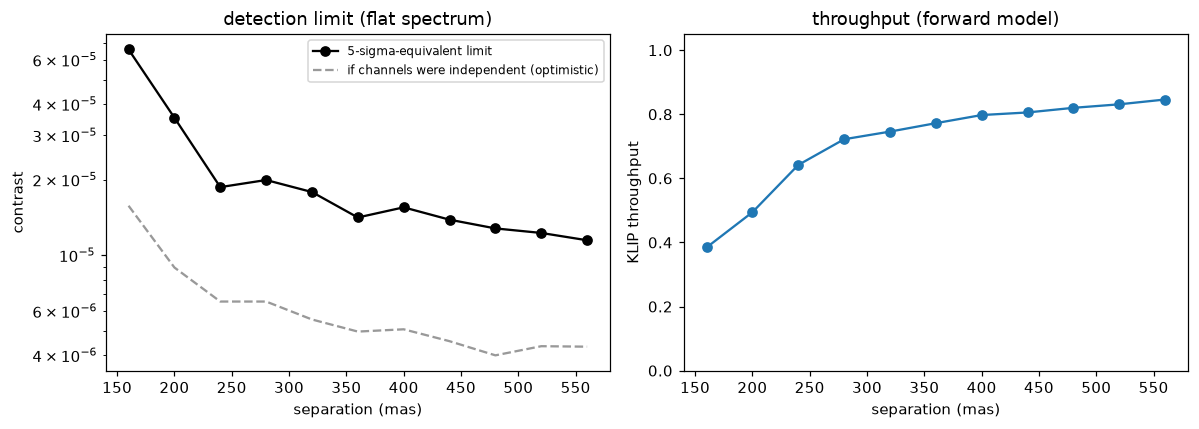

In [6]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax.plot(SEPARATIONS_MAS, limit, "o-", color="k", label="5-sigma-equivalent limit")
ax.plot(SEPARATIONS_MAS, limit_independent, "--", color="0.6",
        label="if channels were independent (optimistic)")
ax.set(yscale="log", xlabel="separation (mas)", ylabel="contrast",
       title="detection limit (%s spectrum)" % ("assumed" if SPECTRUM_FILE else "flat"))
ax.legend(fontsize=8)
ax2.plot(SEPARATIONS_MAS, throughput, "o-")
ax2.set(xlabel="separation (mas)", ylabel="KLIP throughput", ylim=(0, 1.05),
        title="throughput (forward model)")
plt.tight_layout()
plt.show()

## Save

In [7]:
np.savetxt(OUTPUT_FILE,
           np.column_stack([SEPARATIONS_MAS, limit, limit_independent, throughput,
                            curve["nsig_eff"], n_ring]),
           delimiter=",", fmt=["%.1f", "%.4e", "%.4e", "%.4f", "%.3f", "%d"],
           header="separation_mas,contrast_5sigma,contrast_if_independent,throughput,"
                  "threshold_factor_per_channel,n_ring_positions")
print("wrote", OUTPUT_FILE)

wrote contrast_curve.csv
